# B2B Funded Volume by Client Score Band (Favourable / Neutral / Unfavourable)

1. **Base Scoring set** - clients are scored once using the cohort-based methodology (`B2B_functions_cohort_score.py`, identical to `B2B_Reporting_cohort_score_customDates.ipynb`) for the static scoring window **2025-10-31 to 2026-05-31**.
2. **Classification** - each client's `TotalScore` is banded with the `B2B_Client_Score_Stability_Analysis.ipynb` rule: portfolio baseline **Z** = `TotalScore` on the `All / Total / Total` row; Favourable if `score >= Z x 1.25`, Unfavourable if `score < Z x 0.75`, otherwise Neutral.
3. **Funding periods** - clients funding volume in each period (Q1'24-Q4'25 quarterly, Jan-26 to Aug-26 monthly) are tagged from the Base Scoring set; clients absent from it are tagged **Neutral**.
4. **Output** - stacked 100% bars of the Favourable / Neutral / Unfavourable mix per period, weighted by funded volume (plus a client-count view).

Use the **Python (B2B)** kernel (env: `B2B`).

## 0. User Inputs

`pi_BeginRefFundDt` / `pi_EndRefFundDt = None` keep the same default funding window as the reporting notebook (prior 13 full months from today). The funding window only controls **which clients receive a score row**; CPR/Recap scores and the portfolio Z come from the scoring window.

In [1]:
import calendar
from datetime import date
from pathlib import Path

# Static base scoring window
pi_BeginScoreDt   = date(2025, 10, 31)
pi_EndScoreDt     = date(2026, 5, 31)
pi_BeginRefFundDt = None
pi_EndRefFundDt   = None

# Classification multipliers (same defaults as B2B_Client_Score_Stability_Analysis.ipynb)
FAVOURABLE_MULTIPLIER   = 1.25
UNFAVOURABLE_MULTIPLIER = 0.75

PERIODS = [
    (f"Q{q}'{y}", date(y, 3 * q - 2, 1), date(y, 3 * q, calendar.monthrange(y, 3 * q)[1]))
    for y in (2024, 2025) for q in range(1, 5)
] + [
    (date(2026, m, 1).strftime('%b-%y'), date(2026, m, 1), date(2026, m, calendar.monthrange(2026, m)[1]))
    for m in range(1, 9)
]

OUTPUT_DIR = Path(r"E:\Development\Shashi\B2B-Pricing-Model\Cohort_Analysis\B2B_monitoring")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_TAG = f"score_{pi_BeginScoreDt:%Y%m%d}_{pi_EndScoreDt:%Y%m%d}"

print(f"Score window : {pi_BeginScoreDt} -> {pi_EndScoreDt}")
print(f"Fund window  : {pi_BeginRefFundDt or '(default)'} -> {pi_EndRefFundDt or '(default)'}")
print(f"Periods      : {len(PERIODS)} | {PERIODS[0][1]} -> {PERIODS[-1][2]}")
for label, start, end in PERIODS:
    print(f"  {label:<8} {start} -> {end}")

Score window : 2025-10-31 -> 2026-05-31
Fund window  : (default) -> (default)
Periods      : 16 | 2024-01-01 -> 2026-08-31
  Q1'2024  2024-01-01 -> 2024-03-31
  Q2'2024  2024-04-01 -> 2024-06-30
  Q3'2024  2024-07-01 -> 2024-09-30
  Q4'2024  2024-10-01 -> 2024-12-31
  Q1'2025  2025-01-01 -> 2025-03-31
  Q2'2025  2025-04-01 -> 2025-06-30
  Q3'2025  2025-07-01 -> 2025-09-30
  Q4'2025  2025-10-01 -> 2025-12-31
  Jan-26   2026-01-01 -> 2026-01-31
  Feb-26   2026-02-01 -> 2026-02-28
  Mar-26   2026-03-01 -> 2026-03-31
  Apr-26   2026-04-01 -> 2026-04-30
  May-26   2026-05-01 -> 2026-05-31
  Jun-26   2026-06-01 -> 2026-06-30
  Jul-26   2026-07-01 -> 2026-07-31
  Aug-26   2026-08-01 -> 2026-08-31


## 1. Imports & Connection

In [2]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator, PercentFormatter
from sqlalchemy import text

FUNCTIONS_DIR = os.path.join(os.getcwd(), 'functions')
if FUNCTIONS_DIR not in sys.path:
    sys.path.insert(0, FUNCTIONS_DIR)

import B2B_functions_cohort_score as bf
from B2B_functions_cohort_score import B2BPricingReporter, sql_connection

engine = sql_connection(
    server='VMC2VMDBRADC01P',
    database='Analytics_Rpt',
    driver='ODBC Driver 17 for SQL Server',
)
CLASS_ORDER = ['Favourable', 'Neutral', 'Unfavourable']
print('Functions module:', bf.__file__)

Functions module: e:\Development\Shashi\B2B-Pricing-Model\repo\python\functions\B2B_functions_cohort_score.py


## 2. Data Pull — Base Scoring (static window)

Same calls as `B2B_Reporting_cohort_score_customDates.ipynb`: `reporter.load(...)` followed by `run_all_metrics(METRIC_ORDER, product='All')`, i.e. the in-memory equivalent of the `rawTotal` sheet.

In [3]:
reporter = B2BPricingReporter(engine).load(
    begin_score_dt=pi_BeginScoreDt,
    end_score_dt=pi_EndScoreDt,
    begin_fund_dt=pi_BeginRefFundDt,
    end_fund_dt=pi_EndRefFundDt,
)
print('volume_all  :', reporter.volume_all.shape)
print('perform_all :', reporter.perform_all.shape)

METRIC_ORDER = ['Total', 'State', 'FICO', 'LTV', 'DTI', 'Interest Rate',
                'Product', 'Avg Loan Bal', 'Channel', 'Client']
raw_total = reporter.run_all_metrics(METRIC_ORDER, product='All')
print('raw_total   :', raw_total.shape)

Report as of  : current
Funding window: 2025-10-01  →  2026-09-30
Score window  : 2025-10-31  →  2026-05-31
volume_all  : (150664, 18)
perform_all : (2560508, 29)
raw_total   : (928, 35)


## 3. Classify Clients — Base Scoring Set

Logic from `B2B_Client_Score_Stability_Analysis.ipynb` (`derive_score_thresholds` + `assign_score_band`, `TotalScore`, higher is favourable):
- **Z** = `TotalScore` on the single `ProductCategory='All'`, `MetricName='Total'`, `MetricValue='Total'` row
- **Favourable**: `TotalScore >= Z x 1.25`
- **Unfavourable**: `TotalScore < Z x 0.75` (strict)
- **Neutral**: otherwise

In [4]:
def derive_score_thresholds(frame, score_column='TotalScore'):
    totals = frame.loc[
        frame['MetricName'].eq('Total')
        & frame['MetricValue'].eq('Total')
        & frame['ProductCategory'].eq('All'),
        score_column,
    ]
    if len(totals) != 1:
        raise ValueError(f'Expected one All/Total/Total portfolio row, found {len(totals)}')
    baseline = pd.to_numeric(totals, errors='coerce').iloc[0]
    if pd.isna(baseline) or not np.isfinite(baseline) or baseline <= 0:
        raise ValueError(f'Portfolio {score_column} baseline must be finite and positive')
    return {
        'Score column': score_column,
        'Z': float(baseline),
        'Upper threshold': float(baseline) * FAVOURABLE_MULTIPLIER,
        'Lower threshold': float(baseline) * UNFAVOURABLE_MULTIPLIER,
    }


def assign_score_band(scores, favourable_threshold, unfavourable_threshold):
    return pd.Series(
        np.select(
            [scores.ge(favourable_threshold), scores.lt(unfavourable_threshold)],
            ['Favourable', 'Unfavourable'],
            default='Neutral',
        ),
        index=scores.index,
        dtype='object',
    )


def client_key(series):
    return series.astype(str).str.strip().str.upper()


thresholds = derive_score_thresholds(raw_total)

base_scoring_set = (
    raw_total.loc[raw_total['MetricName'].eq('Client'),
                  ['MetricValue', 'LoanCt', 'FundedLoanAmt', 'VolumeRank',
                   'CPRScore', 'RecapScore', 'TotalScore']]
    .rename(columns={'MetricValue': 'Client'})
    .reset_index(drop=True)
)
base_scoring_set['ClientKey'] = client_key(base_scoring_set['Client'])

assert base_scoring_set['Client'].notna().all(), 'Missing client identifiers'
assert not base_scoring_set['ClientKey'].duplicated().any(), 'Duplicate clients in Base Scoring set'
assert np.isfinite(pd.to_numeric(base_scoring_set['TotalScore'], errors='coerce')).all(), \
    'Missing or non-finite TotalScore'

base_scoring_set['ScoreBand'] = assign_score_band(
    base_scoring_set['TotalScore'], thresholds['Upper threshold'], thresholds['Lower threshold'],
)

# Boundary check: lower cutoff is Neutral, just below is Unfavourable, upper cutoff is Favourable
lo, hi = thresholds['Lower threshold'], thresholds['Upper threshold']
assert assign_score_band(pd.Series([np.nextafter(lo, -np.inf), lo, hi]), hi, lo).tolist() == \
    ['Unfavourable', 'Neutral', 'Favourable']

print(f"Base Scoring set: {len(base_scoring_set):,} clients")
display(pd.DataFrame([thresholds]).style.format(
    {c: '{:.6f}' for c in ['Z', 'Upper threshold', 'Lower threshold']}).hide(axis='index'))

Base Scoring set: 807 clients


Score column,Z,Upper threshold,Lower threshold
TotalScore,1.002066,1.252582,0.751549


In [5]:
base_band_mix = (
    base_scoring_set.groupby('ScoreBand')
    .agg(Clients=('Client', 'size'), FundedLoanAmt=('FundedLoanAmt', 'sum'))
    .reindex(CLASS_ORDER, fill_value=0)
)
base_band_mix['Client %'] = base_band_mix['Clients'] / base_band_mix['Clients'].sum()
base_band_mix['Funded %'] = base_band_mix['FundedLoanAmt'] / base_band_mix['FundedLoanAmt'].sum()
print(f"Base funding window: {reporter.begin_fund_dt} -> {reporter.end_fund_dt}")
display(base_band_mix.style.format({
    'Clients': '{:,}', 'FundedLoanAmt': '${:,.0f}', 'Client %': '{:.1%}', 'Funded %': '{:.1%}',
}))

Base funding window: 2025-10-01 -> 2026-09-30


,Clients,FundedLoanAmt,Client %,Funded %
ScoreBand,,,,
Favourable,269,"$23,846,214,569",33.3%,43.4%
Neutral,237,"$13,546,948,946",29.4%,24.6%
Unfavourable,301,"$17,565,642,201",37.3%,32.0%


## 4. Data Pull — Client Funded Volume by Period

One query at Client × funding-month grain with the **same filters as `build_volume_summary_all`** (Correspondent / Co-Issue, non-Reverse, `FundedLoanAmt > 0`, excluding XFER / Bulk loans), then rolled up to the 16 reporting periods.

In [6]:
query_period_volume = text("""
    SELECT a.Client,
           EOMONTH(a.FundDt)    AS FundMonth,
           COUNT(*)             AS LoanCt,
           SUM(a.FundedLoanAmt) AS FundedLoanAmt
    FROM adm.ODS.vwOrigLoan a
    WHERE a.Channel IN ('Correspondent', 'Co-Issue')
      AND a.Client IS NOT NULL
      AND a.FundDt BETWEEN :begin_dt AND :end_dt
      AND a.FundedLoanAmt > 0
      AND a.MortgageType <> 'Reverse'
      AND NOT EXISTS (
          SELECT 1 FROM Analytics_Rpt.md.B2BPricingHist h
          WHERE h.LoanNum = a.LoanNum
            AND (h.ResolType = 'XFER' OR h.Channel = 'Bulk')
      )
    GROUP BY a.Client, EOMONTH(a.FundDt)
""")
period_volume_monthly = pd.read_sql(
    query_period_volume, engine,
    params={'begin_dt': PERIODS[0][1], 'end_dt': PERIODS[-1][2]},
)
period_volume_monthly['FundMonth'] = pd.to_datetime(period_volume_monthly['FundMonth']).dt.to_period('M')
print('period_volume_monthly:', period_volume_monthly.shape)

period_map = pd.DataFrame([
    {'FundMonth': month, 'PeriodOrder': order, 'Period': label}
    for order, (label, start, end) in enumerate(PERIODS)
    for month in pd.period_range(start, end, freq='M')
])
client_period = (
    period_volume_monthly
    .merge(period_map, on='FundMonth', how='left', validate='many_to_one')
    .groupby(['PeriodOrder', 'Period', 'Client'], as_index=False)[['LoanCt', 'FundedLoanAmt']]
    .sum()
)
print('client_period        :', client_period.shape)

period_volume_monthly: (18311, 4)
client_period        : (10131, 5)


## 5. Data Quality

- Every funding month maps to exactly one period and every period has volume
- Period pull reconciles to the reporter's own `build_volume_summary_all` for a test window (Q1'2026), at client level

In [7]:
assert not period_map['FundMonth'].duplicated().any(), 'Overlapping periods'
assert period_volume_monthly['FundMonth'].isin(period_map['FundMonth']).all(), 'Unmapped funding months'
missing_months = sorted(set(period_map['FundMonth']) - set(period_volume_monthly['FundMonth']))
assert not missing_months, f'Funding months with no volume: {missing_months}'
assert np.isclose(client_period['FundedLoanAmt'].sum(), period_volume_monthly['FundedLoanAmt'].sum())

# Reconcile Q1'2026 against the reporter's volume builder
recon_start, recon_end = date(2026, 1, 1), date(2026, 3, 31)
recon_reporter = (
    reporter.build_volume_summary_all(recon_start, recon_end)
    .groupby('Client')[['LoanCt', 'FundedLoanAmt']].sum()
)
recon_months = pd.period_range(recon_start, recon_end, freq='M')
recon_pull = (
    period_volume_monthly[period_volume_monthly['FundMonth'].isin(recon_months)]
    .groupby('Client')[['LoanCt', 'FundedLoanAmt']].sum()
)
recon = recon_reporter.join(recon_pull, how='outer', lsuffix='_reporter', rsuffix='_pull').fillna(0)
assert (recon['LoanCt_reporter'] == recon['LoanCt_pull']).all(), 'LoanCt mismatch vs reporter'
assert np.allclose(recon['FundedLoanAmt_reporter'], recon['FundedLoanAmt_pull'], atol=0.01), \
    'FundedLoanAmt mismatch vs reporter'
print(f"Reconciliation Q1'2026: {len(recon):,} clients, "
      f"{int(recon['LoanCt_pull'].sum()):,} loans, ${recon['FundedLoanAmt_pull'].sum():,.0f} - PASS")

period_dq = (
    client_period.groupby(['PeriodOrder', 'Period'])
    .agg(Clients=('Client', 'nunique'), LoanCt=('LoanCt', 'sum'), FundedLoanAmt=('FundedLoanAmt', 'sum'))
    .droplevel('PeriodOrder')
)
display(period_dq.style.format({'Clients': '{:,}', 'LoanCt': '{:,}', 'FundedLoanAmt': '${:,.0f}'}))

Reconciliation Q1'2026: 723 clients, 36,519 loans, $12,883,860,340 - PASS


,Clients,LoanCt,FundedLoanAmt
Period,,,
Q1'2024,596,"11,595","$3,935,482,665"
Q2'2024,656,"18,338","$6,071,336,785"
Q3'2024,660,"21,561","$7,632,263,605"
Q4'2024,671,"24,066","$8,824,839,907"
Q1'2025,660,"16,029","$6,259,353,546"
Q2'2025,673,"22,555","$8,782,298,391"
Q3'2025,700,"28,312","$11,162,305,815"
Q4'2025,715,"33,610","$13,399,564,413"
Jan-26,574,"8,764","$3,468,448,880"


## 6. Analysis — Tag Period Clients from the Base Scoring Set

Clients are matched on a trimmed, upper-cased client name. Clients not in the Base Scoring set are tagged **Neutral**; their share is reported so the default's impact is visible.

In [8]:
client_period['ClientKey'] = client_key(client_period['Client'])
assert not client_period.duplicated(['PeriodOrder', 'ClientKey']).any(), 'Client name collision after normalization'

tagged = client_period.merge(
    base_scoring_set[['ClientKey', 'TotalScore', 'ScoreBand']],
    on='ClientKey', how='left', validate='many_to_one',
)
tagged['InBaseSet'] = tagged['ScoreBand'].notna()
tagged['ScoreBand'] = tagged['ScoreBand'].fillna('Neutral')
assert len(tagged) == len(client_period)
assert np.isclose(tagged['FundedLoanAmt'].sum(), client_period['FundedLoanAmt'].sum())


def band_share(frame, value=None):
    pivot = frame.pivot_table(
        index=['PeriodOrder', 'Period'], columns='ScoreBand', values=value or 'Client',
        aggfunc='sum' if value else 'size', fill_value=0,
    ).reindex(columns=CLASS_ORDER, fill_value=0).droplevel('PeriodOrder')
    pivot.columns.name = None
    return pivot, pivot.div(pivot.sum(axis=1), axis=0)


volume_amt, volume_share = band_share(tagged, 'FundedLoanAmt')
client_cnt, client_share = band_share(tagged)
assert np.allclose(volume_share.sum(axis=1), 1) and np.allclose(client_share.sum(axis=1), 1)
assert np.allclose(volume_amt.sum(axis=1), period_dq['FundedLoanAmt'])
assert (client_cnt.sum(axis=1) == period_dq['Clients']).all()

coverage = (
    tagged.assign(UntaggedAmt=tagged['FundedLoanAmt'].where(~tagged['InBaseSet'], 0))
    .groupby(['PeriodOrder', 'Period'])
    .agg(Clients=('Client', 'size'), UntaggedClients=('InBaseSet', lambda s: int((~s).sum())),
         FundedLoanAmt=('FundedLoanAmt', 'sum'), UntaggedAmt=('UntaggedAmt', 'sum'))
    .droplevel('PeriodOrder')
)
coverage['Untagged Client %'] = coverage['UntaggedClients'] / coverage['Clients']
coverage['Untagged Volume %'] = coverage['UntaggedAmt'] / coverage['FundedLoanAmt']

display(Markdown('### Funded-volume mix by period'))
display(volume_share.style.format('{:.1%}'))
display(Markdown('### Coverage — clients defaulted to Neutral (not in Base Scoring set)'))
display(coverage.style.format({
    'Clients': '{:,}', 'UntaggedClients': '{:,}', 'FundedLoanAmt': '${:,.0f}', 'UntaggedAmt': '${:,.0f}',
    'Untagged Client %': '{:.1%}', 'Untagged Volume %': '{:.1%}',
}))

### Funded-volume mix by period

,Favourable,Neutral,Unfavourable
Period,,,
Q1'2024,29.9%,32.6%,37.6%
Q2'2024,32.3%,26.3%,41.4%
Q3'2024,27.4%,26.7%,45.9%
Q4'2024,27.6%,24.7%,47.7%
Q1'2025,24.5%,28.5%,46.9%
Q2'2025,29.4%,25.3%,45.3%
Q3'2025,36.2%,24.7%,39.1%
Q4'2025,34.6%,25.5%,39.9%
Jan-26,42.2%,19.3%,38.5%


### Coverage — clients defaulted to Neutral (not in Base Scoring set)

,Clients,UntaggedClients,FundedLoanAmt,UntaggedAmt,Untagged Client %,Untagged Volume %
Period,,,,,,
Q1'2024,596,80,"$3,935,482,665","$276,665,089",13.4%,7.0%
Q2'2024,656,82,"$6,071,336,785","$255,217,667",12.5%,4.2%
Q3'2024,660,73,"$7,632,263,605","$264,691,969",11.1%,3.5%
Q4'2024,671,56,"$8,824,839,907","$218,029,495",8.3%,2.5%
Q1'2025,660,47,"$6,259,353,546","$128,498,566",7.1%,2.1%
Q2'2025,673,31,"$8,782,298,391","$122,394,490",4.6%,1.4%
Q3'2025,700,16,"$11,162,305,815","$55,547,900",2.3%,0.5%
Q4'2025,715,0,"$13,399,564,413",$0,0.0%,0.0%
Jan-26,574,0,"$3,468,448,880",$0,0.0%,0.0%


## 7. Visualizations

Primary chart (recreates the business view): % of **funded volume** by band. A client-count version follows for reference.

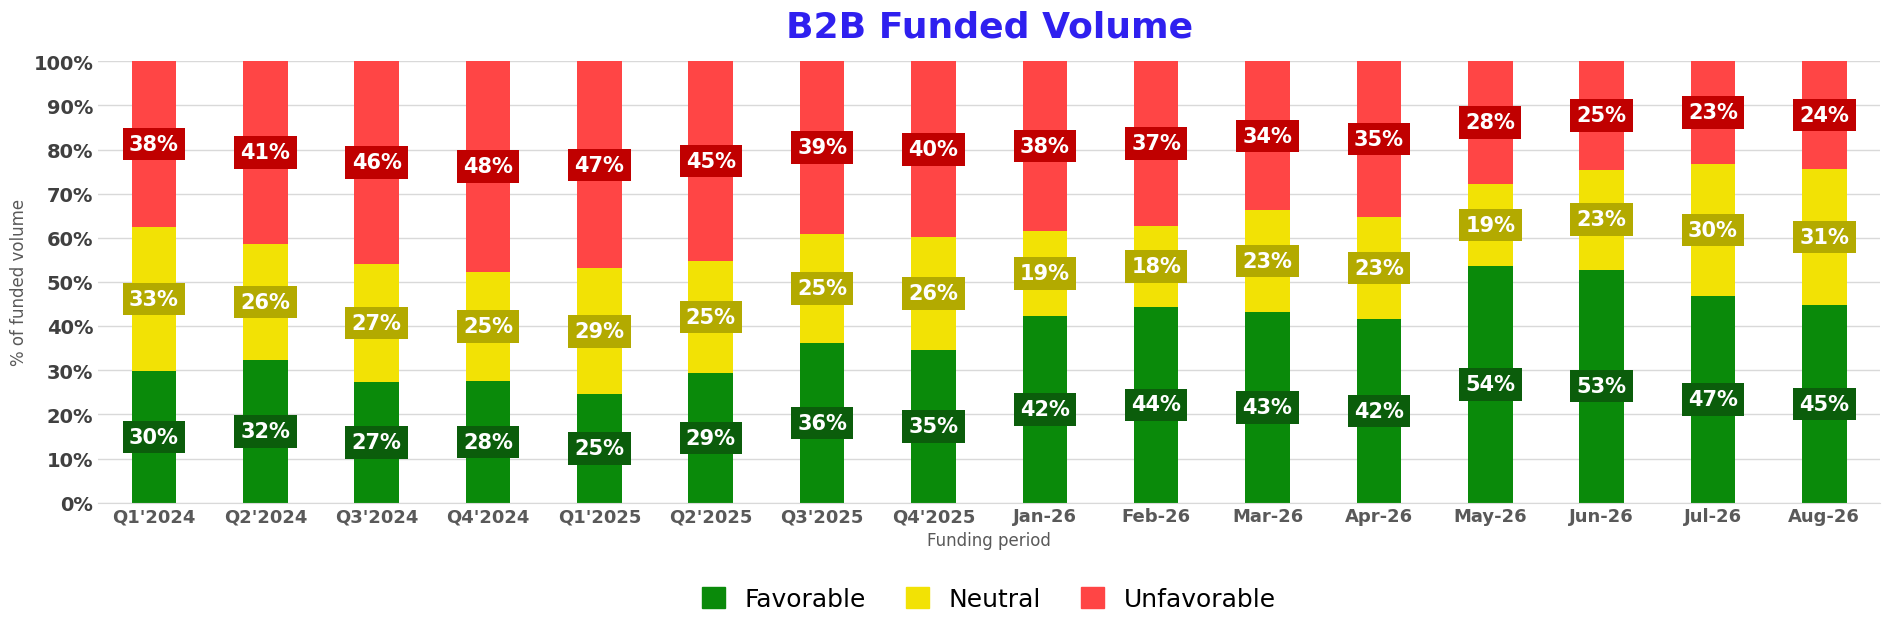

In [9]:
BAND_STYLE = {
    'Favourable':   {'face': '#0A8A0A', 'box': '#0B5D0B', 'legend': 'Favorable'},
    'Neutral':      {'face': '#F2E205', 'box': '#B3AA00', 'legend': 'Neutral'},
    'Unfavourable': {'face': '#FF4545', 'box': '#C00000', 'legend': 'Unfavorable'},
}


def plot_band_mix(shares, title, ylabel, path):
    fig, ax = plt.subplots(figsize=(19, 6.5))
    x = np.arange(len(shares))
    bottom = np.zeros(len(shares))
    for band in CLASS_ORDER:
        style = BAND_STYLE[band]
        values = shares[band].to_numpy()
        ax.bar(x, values, width=0.4, bottom=bottom, color=style['face'], zorder=2)
        for xi, base, value in zip(x, bottom, values):
            if value >= 0.02:
                ax.text(xi, base + value / 2, f'{value:.0%}', ha='center', va='center',
                        fontsize=15, fontweight='bold', color='white', zorder=3,
                        bbox={'boxstyle': 'square,pad=0.3', 'facecolor': style['box'], 'edgecolor': 'none'})
        bottom += values

    ax.set_xticks(x, shares.index, fontsize=13, fontweight='bold', color='#595959')
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_locator(MultipleLocator(0.1))
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.tick_params(axis='y', labelsize=14, colors='#404040')
    for label in ax.get_yticklabels():
        label.set_fontweight('bold')
    ax.tick_params(length=0)
    ax.grid(axis='y', color='#D9D9D9', linewidth=1, zorder=0)
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.spines['bottom'].set_color('#D9D9D9')
    ax.set_xlim(-0.5, len(shares) - 0.5)

    plt.title(title, fontsize=26, fontweight='bold', color='#2F20EF', pad=18)
    plt.xlabel('Funding period', fontsize=12, color='#595959')
    plt.ylabel(ylabel, fontsize=12, color='#595959')
    ax.legend(handles=[Patch(color=BAND_STYLE[b]['face'], label=BAND_STYLE[b]['legend']) for b in CLASS_ORDER],
              loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=3, frameon=False,
              fontsize=18, handlelength=0.9, handleheight=0.9, columnspacing=1.6)
    plt.tight_layout()
    fig.savefig(path, dpi=200, bbox_inches='tight', facecolor='white')
    plt.show()


plot_band_mix(volume_share, 'B2B Funded Volume', '% of funded volume',
              OUTPUT_DIR / f'b2b_funded_volume_band_mix_{OUTPUT_TAG}.png')

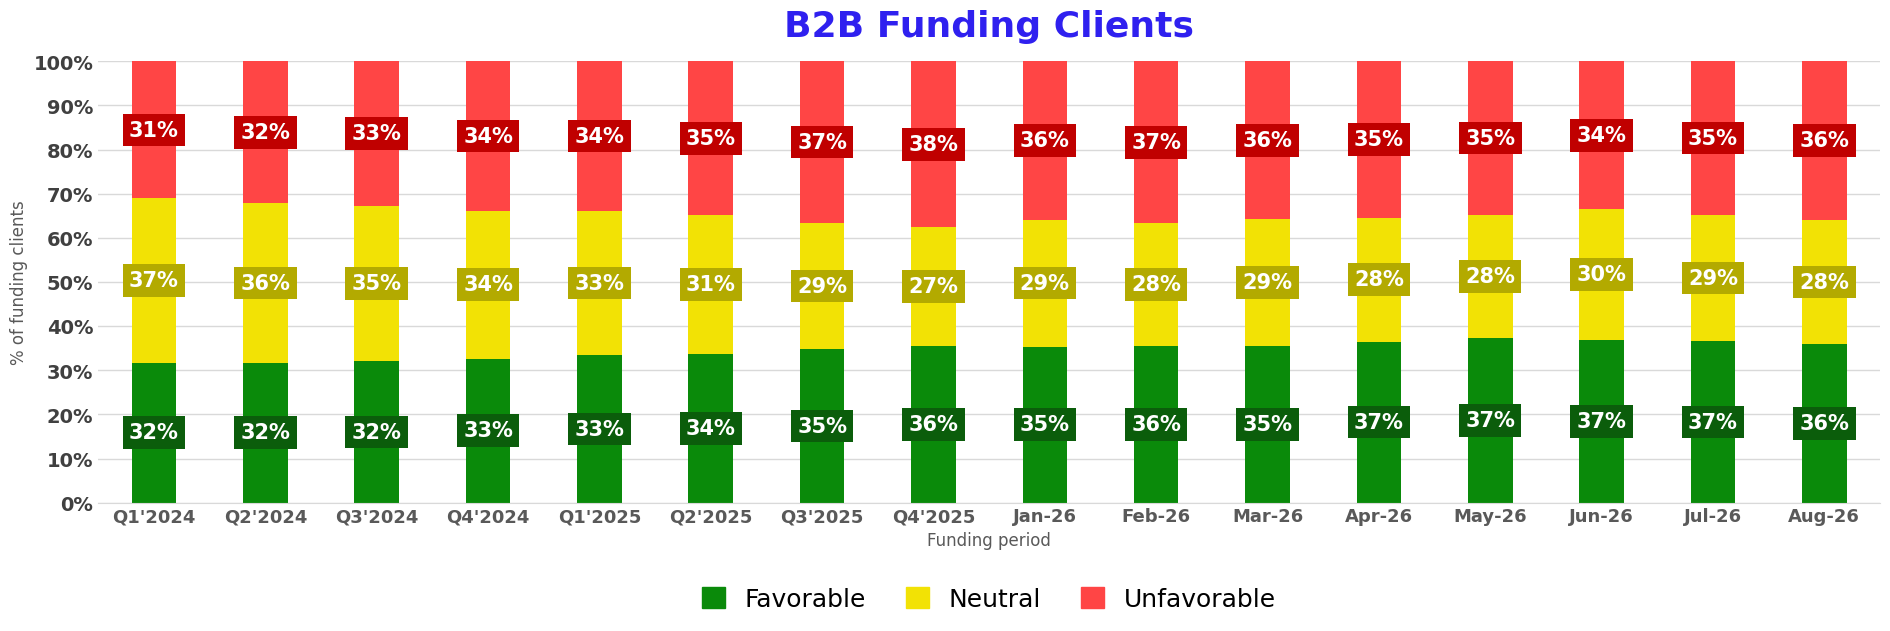

In [10]:
plot_band_mix(client_share, 'B2B Funding Clients', '% of funding clients',
              OUTPUT_DIR / f'b2b_client_count_band_mix_{OUTPUT_TAG}.png')

## 8. Export

In [11]:
export_path = OUTPUT_DIR / f'b2b_funded_volume_band_mix_{OUTPUT_TAG}.xlsx'
with pd.ExcelWriter(export_path) as writer:
    pd.DataFrame([{**thresholds,
                   'Favourable multiplier': FAVOURABLE_MULTIPLIER,
                   'Unfavourable multiplier': UNFAVOURABLE_MULTIPLIER,
                   'BeginScoreDt': pi_BeginScoreDt, 'EndScoreDt': pi_EndScoreDt,
                   'BeginFundDt': reporter.begin_fund_dt, 'EndFundDt': reporter.end_fund_dt}]
                 ).to_excel(writer, sheet_name='Thresholds', index=False)
    base_scoring_set.drop(columns='ClientKey').to_excel(writer, sheet_name='BaseScoringSet', index=False)
    volume_share.to_excel(writer, sheet_name='VolumeShare')
    volume_amt.to_excel(writer, sheet_name='VolumeAmt')
    client_share.to_excel(writer, sheet_name='ClientShare')
    client_cnt.to_excel(writer, sheet_name='ClientCount')
    coverage.to_excel(writer, sheet_name='Coverage')
    tagged.drop(columns=['ClientKey', 'PeriodOrder']).to_excel(writer, sheet_name='ClientPeriodTagged', index=False)

pd.testing.assert_frame_equal(
    pd.read_excel(export_path, sheet_name='VolumeShare', index_col=0).rename_axis('Period'),
    volume_share, check_names=False,
)
print(f'Excel saved: {export_path}')

Excel saved: E:\Development\Shashi\B2B-Pricing-Model\Cohort_Analysis\B2B_monitoring\b2b_funded_volume_band_mix_score_20251031_20260531.xlsx


## 9. Key Takeaways

In [12]:
first, last = volume_share.index[0], volume_share.index[-1]
fav, unf = volume_share['Favourable'], volume_share['Unfavourable']
display(Markdown(f"""
- **Scoring basis:** {len(base_scoring_set):,} clients scored on {pi_BeginScoreDt:%b-%y} to {pi_EndScoreDt:%b-%y} performance; Z = {thresholds['Z']:.4f} (Favourable >= {thresholds['Upper threshold']:.4f}, Unfavourable < {thresholds['Lower threshold']:.4f}).
- **Favourable share of funded volume:** {fav[first]:.1%} in {first} vs {fav[last]:.1%} in {last}; peak {fav.max():.1%} ({fav.idxmax()}), low {fav.min():.1%} ({fav.idxmin()}).
- **Unfavourable share of funded volume:** {unf[first]:.1%} in {first} vs {unf[last]:.1%} in {last}; peak {unf.max():.1%} ({unf.idxmax()}), low {unf.min():.1%} ({unf.idxmin()}).
- **Neutral default impact:** clients outside the Base Scoring set account for {coverage['Untagged Volume %'].min():.1%}-{coverage['Untagged Volume %'].max():.1%} of period volume (highest in {coverage['Untagged Volume %'].idxmax()}); this volume is shown as Neutral.
- **Interpretation:** bands are fixed from a single scoring window, so the trend reflects shifts in *which clients* fund volume, not changes in client scores. Periods before the scoring window are backward-looking applications of current scores.
"""))


- **Scoring basis:** 807 clients scored on Oct-25 to May-26 performance; Z = 1.0021 (Favourable >= 1.2526, Unfavourable < 0.7515).
- **Favourable share of funded volume:** 29.9% in Q1'2024 vs 44.7% in Aug-26; peak 53.6% (May-26), low 24.5% (Q1'2025).
- **Unfavourable share of funded volume:** 37.6% in Q1'2024 vs 24.3% in Aug-26; peak 47.7% (Q4'2024), low 23.2% (Jul-26).
- **Neutral default impact:** clients outside the Base Scoring set account for 0.0%-7.0% of period volume (highest in Q1'2024); this volume is shown as Neutral.
- **Interpretation:** bands are fixed from a single scoring window, so the trend reflects shifts in *which clients* fund volume, not changes in client scores. Periods before the scoring window are backward-looking applications of current scores.
